# 07 · Where does the model go wrong, and why?

The frozen bundle (Phase 8: gradient boosting + calibration + expected-cost policy) on
**validation** (Jul–Sep 2025). The test period has been used once and is not analysed here:
studying its errors to change the model would turn it into another validation set.

Output of `fraud analyse validation` (`data/processed/phase9/`).

Errors are defined at the decision the business experiences:
- **false positive**: a payment labelled legit that was **blocked**;
- **false negative**: a payment labelled fraud that was **approved**.

The simulator's ground truth (true scenario of each payment) is used only here, to explain
the errors. It is never a model input.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fraudplatform.config import PROJECT_ROOT
from fraudplatform.eda import plots
from fraudplatform.features.catalog import FEATURES

plots.apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
run_dir = PROJECT_ROOT / "data" / "processed" / "phase9"
summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
decisions = pd.read_parquet(run_dir / "validation_decisions.parquet")
group_of = {f.name: f.group for f in FEATURES}
decisions["outcome"].value_counts().to_frame("transactions")

,transactions
outcome,
legit approved,355002
fraud blocked,2058
legit reviewed,1155
legit blocked (FP),455
fraud approved (FN),429
fraud reviewed,121


## 1. How much of the "error" is the label, not the model?

Labels are noisy on purpose (as in reality): some fraud is never reported, and some legit
payments are disputed as fraud. Cross-tabulating the decision outcome with that noise:

In [2]:
pd.crosstab(decisions["outcome"], decisions["label_noise"], margins=True)

label_noise,friendly fraud,none,unreported fraud,All
outcome,,,,
fraud approved (FN),153,276,0,429
fraud blocked,0,2058,0,2058
fraud reviewed,0,121,0,121
legit approved,0,354915,87,355002
legit blocked (FP),0,128,327,455
legit reviewed,0,1115,40,1155
All,153,358613,454,359220


## 2. What drives the model? Global importance

**Permutation importance**: drop in PR-AUC when a column (or a whole family of columns,
shuffled together) is randomly shuffled on validation. 5 repetitions; the error bar is the
standard deviation.

,group,features,importance,std
0,entity,7,0.1689,0.0014
1,transaction,10,0.1640,0.0039
2,device,4,0.1020,0.0032
3,customer_behaviour,8,0.0555,0.0033
4,card_velocity,10,0.0447,0.0013
5,labels_as_of,5,0.0343,0.0015
6,geo,5,0.0111,0.0002


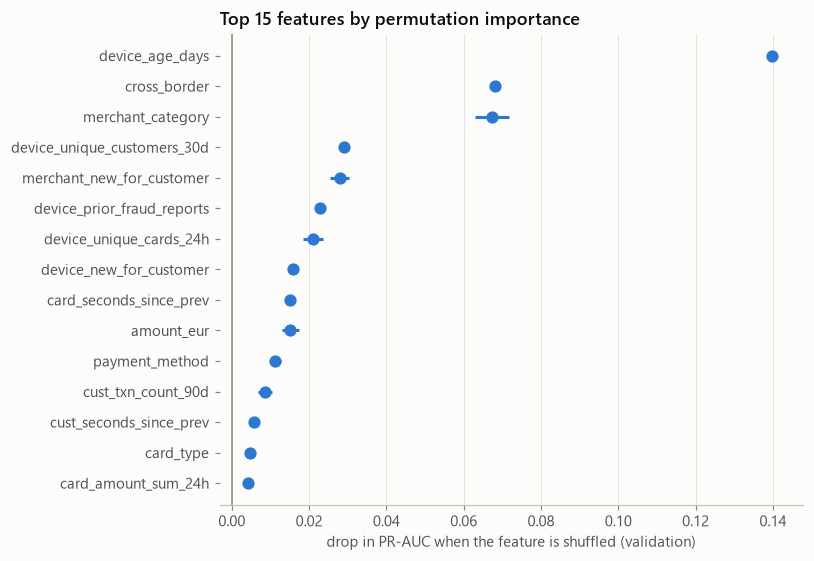

,importance,std,group
device_age_days,0.1397,0.0012,entity
cross_border,0.0680,0.0008,transaction
merchant_category,0.0673,0.0044,transaction
device_unique_customers_30d,0.0289,0.0007,device
merchant_new_for_customer,0.0279,0.0024,customer_behaviour
device_prior_fraud_reports,0.0227,0.0009,labels_as_of
device_unique_cards_24h,0.0209,0.0026,device
device_new_for_customer,0.0158,0.0012,device
card_seconds_since_prev,0.0152,0.0008,card_velocity
amount_eur,0.0151,0.0022,transaction


In [3]:
grouped = pd.read_csv(run_dir / "permutation_grouped.csv")
display(grouped.style.format({"importance": "{:.4f}", "std": "{:.4f}"}))
single = pd.read_csv(run_dir / "permutation_single.csv", index_col=0)
single["group"] = single.index.map(group_of)
top = single.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
y = np.arange(len(top))
ax.errorbar(
    top["importance"],
    y,
    xerr=top["std"],
    fmt="o",
    color=plots.BLUE,
    markersize=7,
    elinewidth=2,
    capsize=0,
)
ax.set_yticks(y, top.index)
ax.axvline(0, color=plots.MUTED, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("drop in PR-AUC when the feature is shuffled (validation)")
ax.set_title("Top 15 features by permutation importance")
fig.tight_layout()
plots.save(fig, "permutation_importance_top15", folder="analysis")
plt.show()
single.head(15).style.format({"importance": "{:.4f}", "std": "{:.4f}"})

**SHAP values** (exact, additivity-checked) on a sample of 900 validation payments covering
every kind of decision. Mean |SHAP| measures how much a feature moves individual
predictions, in log-odds. It is a different question from permutation importance (how much
the *ranking quality* depends on the feature), so the two orders need not agree.

In [4]:
shap_sample = pd.read_parquet(run_dir / "shap_sample.parquet")
shap_cols = [c for c in shap_sample.columns if c.startswith("shap__")]
mean_abs = shap_sample[shap_cols].abs().mean().sort_values(ascending=False)
mean_abs.index = mean_abs.index.str.removeprefix("shap__")
print(f"SHAP additivity error (max over the sample): {summary['shap_additivity_error']:.1e}")
comparison = pd.DataFrame({"mean_abs_shap": mean_abs.head(15)})
comparison["permutation_rank"] = [single.index.get_loc(f) + 1 for f in comparison.index]
comparison.style.format({"mean_abs_shap": "{:.3f}"})

SHAP additivity error (max over the sample): 4.1e-14


,mean_abs_shap,permutation_rank
device_age_days,0.843,1
cross_border,0.454,2
merchant_category,0.424,3
device_prior_fraud_reports,0.421,6
card_seconds_since_prev,0.379,9
payment_method,0.321,11
device_unique_customers_30d,0.277,4
cust_seconds_since_prev,0.274,13
cust_txn_count_90d,0.226,12
amount_eur,0.216,10


## 3. Explaining single decisions

Three real validation payments: a fraud the policy blocked with high confidence, a legit
payment it blocked (false positive), and the largest fraud it approved (false negative).
Each bar is how much that feature pushed the log-odds up (towards fraud) or down.

fraud blocked (most confident): amount €444.03, p = 0.9877, base -6.92 + contributions = log-odds 4.18


,value,shap_log_odds
cross_border,1.000000,+2.63
card_seconds_since_prev,5288.000000,+1.40
cust_seconds_since_prev,5288.000000,+1.11
card_amount_sum_24h,369.960000,+0.89
card_type,virtual,+0.80
merchant_txn_count_90d,5,+0.48
local_hour,2,+0.41
amount_eur,444.030000,+0.41


legit blocked (false positive): amount €284.48, p = 0.9782, base -6.92 + contributions = log-odds 3.61


,value,shap_log_odds
device_age_days,0.359491,+1.79
merchant_category,gift_cards,+1.19
cross_border,1.000000,+1.07
card_amount_sum_1h,658.140000,+0.96
card_seconds_since_prev,2334.000000,+0.75
card_txn_count_24h,8,+0.71
merchant_fraud_rate_90d_smoothed,0.092037,+0.68
device_unique_cards_24h,1.000000,+0.60


fraud approved (largest false negative): amount €766.88, p = 0.0011, base -6.92 + contributions = log-odds -6.63


,value,shap_log_odds
amount_eur,766.880000,+0.20
device_age_days,nan,+0.16
customer_segment,premium,-0.15
payment_method,contactless,-0.15
amount_zscore_cust_90d,2.241891,+0.15
amount_to_cust_median_90d,10.540581,+0.14
cust_seconds_since_prev,94645.000000,+0.12
card_type,credit,+0.10


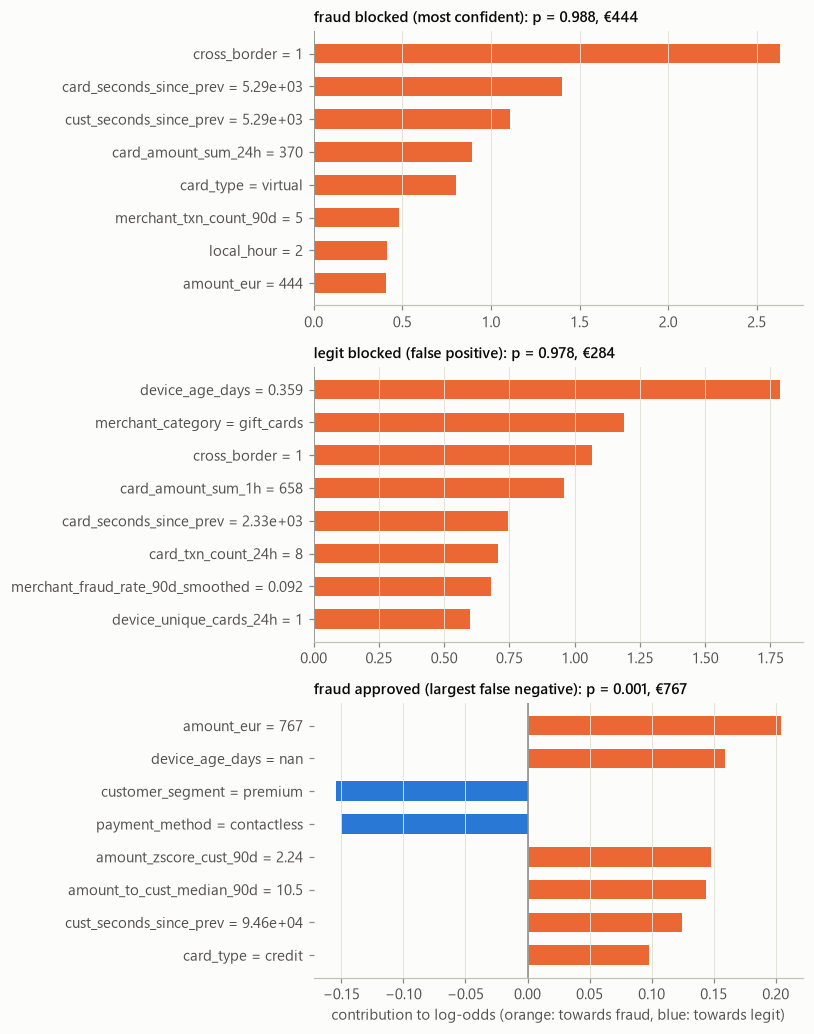

In [5]:
def explain_row(row: pd.Series, top_n: int = 8) -> pd.DataFrame:
    contrib = row[shap_cols].astype(float)
    contrib.index = contrib.index.str.removeprefix("shap__")
    order = contrib.abs().sort_values(ascending=False).index[:top_n]
    return pd.DataFrame({"value": [row[f] for f in order], "shap_log_odds": contrib[order]})


examples = {
    "fraud blocked (most confident)": shap_sample[shap_sample["outcome"] == "fraud blocked"]
    .sort_values("p")
    .iloc[-1],
    "legit blocked (false positive)": shap_sample[shap_sample["outcome"] == "legit blocked (FP)"]
    .sort_values("p")
    .iloc[-1],
    "fraud approved (largest false negative)": shap_sample[
        shap_sample["outcome"] == "fraud approved (FN)"
    ]
    .sort_values("amount_eur")
    .iloc[-1],
}
fig, axes = plt.subplots(len(examples), 1, figsize=(7.5, 9.5))
for ax, (title, row) in zip(axes, examples.items(), strict=True):
    table = explain_row(row)
    print(
        f"{title}: amount €{row['amount_eur']:.2f}, p = {row['p']:.4f}, "
        f"base {row['base']:.2f} + contributions = log-odds {row['log_odds']:.2f}"
    )
    display(table.style.format({"shap_log_odds": "{:+.2f}"}))
    t = table.iloc[::-1]
    colors = [plots.ORANGE if v > 0 else plots.BLUE for v in t["shap_log_odds"]]
    ax.barh(np.arange(len(t)), t["shap_log_odds"], color=colors, height=0.6)
    ax.set_yticks(
        np.arange(len(t)),
        [
            f"{f} = {v}" if not isinstance(v, float) else f"{f} = {v:.3g}"
            for f, v in zip(t.index, t["value"], strict=True)
        ],
    )
    ax.axvline(0, color=plots.MUTED, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{title}: p = {row['p']:.3f}, €{row['amount_eur']:.0f}", fontsize=10)
axes[-1].set_xlabel("contribution to log-odds (orange: towards fraud, blue: towards legit)")
fig.tight_layout()
plots.save(fig, "shap_examples", folder="analysis")
plt.show()

**Were these really errors?** The simulator knows the true story of each payment:

In [6]:
truth = decisions.set_index("transaction_id")
pd.DataFrame(
    {
        title: {
            "label": "fraud" if truth.loc[row["transaction_id"], "is_fraud"] else "legit",
            "truth": truth.loc[row["transaction_id"], "scenario"],
            "label noise": truth.loc[row["transaction_id"], "label_noise"],
        }
        for title, row in examples.items()
    }
).T

,label,truth,label noise
fraud blocked (most confident),fraud,card_cloning,none
legit blocked (false positive),legit,card_testing,unreported fraud
fraud approved (largest false negative),fraud,legit,friendly fraud


## 3b. How much of each error type is label noise?

In [7]:
fp = decisions[decisions["outcome"] == "legit blocked (FP)"]
fn = decisions[decisions["outcome"] == "fraud approved (FN)"]
fp_by_band = fp.groupby("amount_band")["label_noise"].apply(
    lambda s: (s == "unreported fraud").mean()
)
display(
    pd.DataFrame(
        {
            "false positives": fp["amount_band"].value_counts(),
            "of which unreported fraud": fp_by_band,
        }
    )
    .style.format({"of which unreported fraud": "{:.0%}"})
    .set_caption("Blocked 'legit' payments that were actually fraud, by amount")
)
fn_truth = fn["scenario"].where(fn["is_fraud_true"], "friendly fraud (truly legit)")
display(
    fn_truth.value_counts()
    .to_frame("false negatives")
    .style.set_caption("Approved 'fraud' payments by their true story")
)
truly_legit = ~decisions["is_fraud_true"]
real_fp = (decisions["outcome"] == "legit blocked (FP)") & (decisions["label_noise"] == "none")
print(f"measured false decline rate: {len(fp) / (~decisions['is_fraud']).sum():.4%}")
print(
    f"real false decline rate:     {real_fp.sum() / truly_legit.sum():.4%} "
    f"({real_fp.sum()} truly legit payments blocked)"
)

,false positives,of which unreported fraud
amount_band,,
100-500,134,43%
20-100,54,44%
< 5,198,100%
>= 500,69,70%


,false negatives
scenario,
stealth,221
friendly fraud (truly legit),153
card_testing,31
card_cloning,22
merchant_compromise,1
account_takeover,1


measured false decline rate: 0.1276%
real false decline rate:     0.0359% (128 truly legit payments blocked)


## 4. False negatives: which fraud gets through?

What happened to each TRUE scenario (simulator truth), split by whether it was labelled.

In [8]:
scenarios = pd.read_csv(run_dir / "scenarios.csv")
scenarios.style.format(
    {
        "blocked": "{:.1%}",
        "reviewed": "{:.1%}",
        "approved": "{:.1%}",
        "median_p": "{:.4f}",
        "median_amount": "€{:,.0f}",
    }
)

,truth,labelled_fraud,transactions,blocked,reviewed,approved,median_p,median_amount
0,account_takeover,False,71,97.2%,1.4%,1.4%,0.9182,€644
1,account_takeover,True,728,98.1%,1.8%,0.1%,0.9312,€554
2,card_cloning,False,20,85.0%,10.0%,5.0%,0.7447,€79
3,card_cloning,True,450,84.0%,11.1%,4.9%,0.8713,€118
4,card_testing,False,279,77.1%,12.9%,10.0%,0.5837,€2
5,card_testing,True,415,80.7%,11.8%,7.5%,0.6139,€3
6,fraud_ring,False,6,100.0%,0.0%,0.0%,0.9015,€85
7,fraud_ring,True,143,98.6%,1.4%,0.0%,0.9273,€98
8,legit,False,356158,0.0%,0.3%,99.7%,0.0008,€41
9,legit,True,153,0.0%,0.0%,100.0%,0.0010,€48


## 5. Where are errors over-represented?

`fp_rate` = share of legit payments in that group that were blocked; `fn_rate` = share of
fraud that was approved. Over-representation 2.0 = twice as common among the errors as in
the population.

In [9]:
for name in [
    "merchant_category",
    "payment_method",
    "border",
    "amount_band",
    "device_type",
    "hour_band",
    "account_age_band",
    "customer_segment",
    "home_country",
]:
    table = pd.read_csv(run_dir / f"profile_{name}.csv", index_col=0)
    display(
        table.style.format(
            {
                "legit": "{:,.0f}",
                "false_positives": "{:,.0f}",
                "fraud": "{:,.0f}",
                "false_negatives": "{:,.0f}",
                "fp_rate": "{:.3%}",
                "fn_rate": "{:.1%}",
                "fp_over_representation": "{:.2f}",
                "fn_over_representation": "{:.2f}",
            }
        ).set_caption(name)
    )

,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
merchant_category,,,,,,,,
grocery,"64,865",30,179,67,0.046%,37.4%,0.36,2.28
restaurants,"41,182",0,59,39,0.000%,66.1%,0.00,4.02
digital_goods,"39,079",190,470,72,0.486%,15.3%,3.81,0.93
fashion,"32,538",26,280,32,0.080%,11.4%,0.63,0.69
entertainment,"29,785",20,95,36,0.067%,37.9%,0.53,2.30
utilities,"28,333",0,37,35,0.000%,94.6%,0.00,5.75
transport,"27,182",0,41,37,0.000%,90.2%,0.00,5.49
travel,"19,445",21,110,24,0.108%,21.8%,0.85,1.33
electronics,"19,436",81,623,21,0.417%,3.4%,3.27,0.20


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
payment_method,,,,,,,,
ecommerce,"150,632",319,"1,717",229,0.212%,13.3%,1.66,0.81
contactless,"90,671",46,250,107,0.051%,42.8%,0.40,2.60
chip_pin,"60,997",62,363,76,0.102%,20.9%,0.80,1.27
mobile_wallet,"54,312",28,278,17,0.052%,6.1%,0.40,0.37


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
border,,,,,,,,
domestic,"341,464",161,"1,112",395,0.047%,35.5%,0.37,2.16
cross-border,"15,148",294,"1,496",34,1.941%,2.3%,15.21,0.14


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
amount_band,,,,,,,,
20-100,"184,987",54,672,225,0.029%,33.5%,0.23,2.04
5-20,"77,122",0,67,58,0.000%,86.6%,0.00,5.26
100-500,"63,985",134,"1,066",86,0.209%,8.1%,1.64,0.49
< 5,"18,149",198,316,44,1.091%,13.9%,8.55,0.85
>= 500,"12,369",69,487,16,0.558%,3.3%,4.37,0.20


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
device_type,,,,,,,,
mobile,"183,276",154,807,213,0.084%,26.4%,0.66,1.60
none,"151,668",108,613,183,0.071%,29.9%,0.56,1.81
desktop,"13,545",174,"1,092",23,1.285%,2.1%,10.07,0.13
tablet,"6,993",14,84,6,0.200%,7.1%,1.57,0.43
unknown,"1,130",5,12,4,0.442%,33.3%,3.47,2.03


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
hour_band,,,,,,,,
12-17,"141,519",151,789,163,0.107%,20.7%,0.84,1.26
18-23,"123,433",126,765,141,0.102%,18.4%,0.80,1.12
06-11,"79,137",107,590,102,0.135%,17.3%,1.06,1.05
00-05,"12,523",71,464,23,0.567%,5.0%,4.44,0.30


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
account_age_band,,,,,,,,
> 3 y,"228,337",279,"1,579",261,0.122%,16.5%,0.96,1.00
1-3 y,"89,119",118,701,114,0.132%,16.3%,1.04,0.99
1-12 m,"35,832",54,299,43,0.151%,14.4%,1.18,0.87
<= 30 d,"3,324",4,29,11,0.120%,37.9%,0.94,2.31


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
customer_segment,,,,,,,,
standard,"179,661",248,"1,442",240,0.138%,16.6%,1.08,1.01
premium,"73,123",86,447,58,0.118%,13.0%,0.92,0.79
small_business,"61,148",60,325,67,0.098%,20.6%,0.77,1.25
student,"42,680",61,394,64,0.143%,16.2%,1.12,0.99


,legit,false_positives,fraud,false_negatives,fp_rate,fn_rate,fp_over_representation,fn_over_representation
home_country,,,,,,,,
ES,"250,032",359,"2,021",315,0.144%,15.6%,1.13,0.95
PT,"20,815",12,108,22,0.058%,20.4%,0.45,1.24
FR,"19,715",16,136,27,0.081%,19.9%,0.64,1.21
IT,"18,110",15,120,16,0.083%,13.3%,0.65,0.81
DE,"14,765",20,86,12,0.135%,14.0%,1.06,0.85
NL,"7,114",9,31,11,0.127%,35.5%,0.99,2.16
GB,"6,617",3,23,8,0.045%,34.8%,0.36,2.11
MX,"4,721",0,14,4,0.000%,28.6%,0.00,1.74
US,"3,977",6,24,6,0.151%,25.0%,1.18,1.52


## 6. Segment analysis

PR-AUC is only computed with at least 30 frauds in the segment.

In [10]:
for name in [
    "channel",
    "payment_method",
    "merchant_category",
    "customer_segment",
    "home_country",
    "account_age_band",
    "customer_age_band",
    "amount_band",
    "border",
]:
    table = pd.read_csv(run_dir / f"segment_{name}.csv", index_col=0)
    display(
        table.style.format(
            {
                "transactions": "{:,}",
                "frauds": "{:,}",
                "fraud_rate": "{:.2%}",
                "pr_auc": "{:.3f}",
                "fraud_stopped": "{:.1%}",
                "fraud_eur_stopped": "{:.1%}",
                "block_precision": "{:.1%}",
                "false_decline_rate": "{:.3%}",
            },
            na_rep="–",
        ).set_caption(name)
    )

,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
channel,,,,,,,,
card not present,"206,939","1,995",0.96%,0.825,87.7%,97.0%,82.9%,0.169%
card present,"152,281",613,0.40%,0.667,70.1%,79.4%,77.8%,0.071%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
payment_method,,,,,,,,
chip_pin,"61,360",363,0.59%,0.750,79.1%,87.4%,80.6%,0.102%
contactless,"90,921",250,0.27%,0.544,57.2%,67.5%,72.6%,0.051%
ecommerce,"152,349","1,717",1.13%,0.813,86.7%,96.1%,81.7%,0.212%
mobile_wallet,"54,590",278,0.51%,0.888,93.9%,99.3%,90.2%,0.052%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
merchant_category,,,,,,,,
digital_goods,"39,549",470,1.19%,0.727,84.7%,97.3%,65.6%,0.486%
electronics,"20,059",623,3.11%,0.909,96.6%,97.5%,87.8%,0.417%
entertainment,"29,880",95,0.32%,0.583,62.1%,57.5%,69.2%,0.067%
fashion,"32,818",280,0.85%,0.857,88.6%,93.0%,90.2%,0.080%
fuel,"18,412",140,0.76%,0.847,87.9%,93.8%,77.9%,0.181%
gift_cards,"6,582",349,5.30%,0.928,98.0%,98.6%,93.6%,0.369%
grocery,"65,044",179,0.28%,0.557,62.6%,79.7%,76.0%,0.046%
health,"12,021",19,0.16%,–,26.3%,48.0%,80.0%,0.008%
home,"14,266",22,0.15%,–,0.0%,0.0%,0.0%,0.007%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
customer_segment,,,,,,,,
premium,"73,570",447,0.61%,0.826,87.0%,95.5%,80.9%,0.118%
small_business,"61,473",325,0.53%,0.754,79.4%,93.9%,79.6%,0.098%
standard,"181,103","1,442",0.80%,0.786,83.4%,95.3%,82.2%,0.138%
student,"43,074",394,0.91%,0.817,83.8%,96.7%,83.7%,0.143%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
home_country,,,,,,,,
BR,"1,621",9,0.56%,–,66.7%,71.8%,100.0%,0.000%
DE,"14,851",86,0.58%,0.806,86.0%,98.5%,77.3%,0.135%
ES,"252,053","2,021",0.80%,0.803,84.4%,95.5%,81.9%,0.144%
FR,"19,851",136,0.69%,0.760,80.1%,90.1%,86.1%,0.081%
GB,"6,640",23,0.35%,–,65.2%,80.4%,82.4%,0.045%
IE,"3,619",25,0.69%,–,88.0%,95.5%,71.4%,0.223%
IT,"18,230",120,0.66%,0.819,86.7%,97.6%,86.7%,0.083%
MA,"1,724",0,0.00%,–,0.0%,0.0%,0.0%,0.058%
MX,"4,735",14,0.30%,–,71.4%,91.7%,100.0%,0.000%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
account_age_band,,,,,,,,
1-12 m,"36,131",299,0.83%,0.809,85.6%,96.3%,81.7%,0.151%
1-3 y,"89,820",701,0.78%,0.800,83.7%,94.4%,82.5%,0.132%
<= 30 d,"3,353",29,0.86%,–,62.1%,87.9%,77.8%,0.120%
> 3 y,"229,916","1,579",0.69%,0.789,83.5%,95.5%,81.7%,0.122%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
customer_age_band,,,,,,,,
18-25,"53,242",461,0.87%,0.821,84.8%,97.0%,85.4%,0.121%
26-35,"54,357",435,0.80%,0.837,85.3%,94.9%,83.9%,0.122%
36-50,"140,297","1,050",0.75%,0.799,84.0%,95.6%,80.8%,0.143%
51-65,"93,643",528,0.56%,0.713,79.9%,93.3%,78.0%,0.119%
66+,"17,681",134,0.76%,0.833,84.3%,95.3%,87.8%,0.085%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
amount_band,,,,,,,,
100-500,"65,051","1,066",1.64%,0.873,91.9%,92.8%,87.5%,0.209%
20-100,"185,659",672,0.36%,0.659,66.5%,70.8%,88.6%,0.029%
5-20,"77,189",67,0.09%,0.140,13.4%,14.0%,100.0%,0.000%
< 5,"18,465",316,1.71%,0.509,86.1%,86.3%,53.3%,1.091%
>= 500,"12,856",487,3.79%,0.889,96.7%,98.0%,87.1%,0.558%


,transactions,frauds,fraud_rate,pr_auc,fraud_stopped,fraud_eur_stopped,block_precision,false_decline_rate
border,,,,,,,,
cross-border,"16,644","1,496",8.99%,0.925,97.7%,99.2%,82.6%,1.941%
domestic,"342,576","1,112",0.32%,0.602,64.5%,90.6%,80.5%,0.047%


## 7. Findings

Full write-up: [`reports/analysis/phase9_findings.md`](../reports/analysis/phase9_findings.md).

- **Most measured errors are label noise.** 327 of 455 blocked "legit" payments are
  unreported fraud (all 198 blocked micro-charges are card testing); the real false decline
  rate is 0.036%, not 0.128%. 153 of 429 approved "fraud" payments are legit disputes.
- **Real misses are mostly stealth fraud** (221), designed to look like the customer, plus
  55 others (card testing and cloning).
- **What drives the model:** device age, cross-border, merchant category, device sharing and
  novelty. The operating system, artificially strong in the data, is not in the top 15.
- **Weak segments:** card-present (PR-AUC 0.667 vs 0.825 online), contactless (0.544),
  domestic (0.602), and €5–20 payments, where approving is the cost-optimal choice.
- **Real false positives** are mostly cross-border purchases of €100–500 by travellers.